# F03.03 · Contexto y normalización por paciente: ¿ayuda mirar más atrás?

![Portada del notebook F03.03](img/portada_notebook_03.png)

> 🧭 **En 30 segundos**
> - **El problema:** en F03.02 el modelo miraba **una ventana de 4 s suelta** y no sabía decir si venía una crisis: acertaba como tirar una moneda (AUC ≈ 0,5).
> - **Lo que probamos aquí:** dos ideas para darle más pistas, **antes** de construir la red neuronal:
>   1. **Contexto:** que mire también los segundos **de antes** de la ventana (8, 16, 32 o 60 s).
>   2. **Cada paciente frente a sí mismo:** que compare cada ventana con **lo normal en esa persona**.
> - **Lo que sale:** qué idea funciona, cuánto, y qué recibirá la red de **F03.04**.

> 📍 **Dónde estamos: Fase 3 · notebook 3 (F03.03).** Venimos de la línea base (F03.02) y vamos hacia la red neuronal (F03.04).

> 🔄 **Es dinámico:** las cifras, la decisión y las conclusiones se calculan solas al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3:** aquí **no se mira 🟢 eval** (el examen final). Todo se decide con 🟡 dev (el examen de práctica).

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Piensa en cómo mira un médico la **tensión arterial**:

1. **Una medida suelta dice poco.** Un 14 puede ser normal en una persona y alto en otra. → Es lo que hacía F03.02: mirar **una** ventana de 4 s, sola. Salió casi al azar.
2. **Hay que compararla con lo normal en esa persona.** "Tú sueles tener 11, así que 14 es alto". → **Normalizar por paciente** (§6).
3. **Y mirar cómo ha ido el último rato.** "Lleva media hora subiendo". → **El contexto** (§3-§5).

Probamos las dos ideas **por separado y juntas**, con los mismos modelos de F03.02. Así respondemos a cuatro preguntas:

| Pregunta | Dónde se responde |
|---|---|
| ¿Ayuda mirar más atrás? ¿Cuánto? | §7 |
| ¿Ayuda comparar a cada paciente consigo mismo? | §7 y §9 |
| ¿Es predicción de verdad, o el modelo solo reconoce la grabación? | §10 |
| ¿Qué se lleva la red de F03.04? | §9 y §14 |

## El recorrido de este notebook

![El recorrido del notebook F03.03](img/mapa_notebook_03.png)

👀 **Qué enseña.** Los pasos, en orden. Los dos en rojo son los importantes: **medir** (§7) y **decidir** (§8-§9). Abajo, la regla para que la comparación sea justa: todo se compara con la línea base de F03.02 (4 s, sin normalizar), medida con **las mismas ventanas**.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Ventana** | Un trozo de 4 s de EEG. Es la unidad que el modelo juzga |
| **⏳ preictal / 💤 interictal** | Ventana de *antes de una crisis* / ventana de un momento *tranquilo*, lejos de las crisis |
| **Contexto** | Los segundos de justo antes de la ventana. Con 60 s, el modelo ve la ventana actual y las 14 anteriores. Ver §3 |
| **Media / variación / cambio** | Cómo se resume el contexto: el valor típico, cuánto se ha movido y si lo de ahora es distinto de lo de antes. Ver §5 |
| **Normalizar por paciente** | Restar a cada número lo normal en ese paciente. Ver §6 |
| **Calibración** | Lo que haría una app al empezar: grabar unos minutos tranquilos del paciente para saber cuál es su "normal" |
| **Fuga** | Que el modelo reciba sin querer una pista de la respuesta. Hace que la nota salga mejor de lo que es. Ver §6.2 |
| **AUC-ROC** | La nota del modelo: 0,5 = azar (moneda), 1 = perfecto. Ver §7 |
| **Intervalo (IC 95 %)** | El margen de error de la nota. Si el intervalo toca el 0,5, puede que el modelo no sirva |
| **Diferencia emparejada** | Comparar dos modelos con exactamente las mismas ventanas y pacientes, para saber si uno es mejor de verdad. Ver §9 |
| **🔵 train / 🟡 dev / 🟢 eval** | Los tres grupos de pacientes: con el primero se aprende, con el segundo se practica y decide, y el tercero es el examen final (aquí no se toca) |

## 0. El parámetro: qué conjunto se usa

> 🎯 **Qué hacemos:** elegir con qué datos se trabaja.

- `general`: el modelo principal, con todos los tipos de crisis.
- `grupo_ausencia`: solo las crisis de ausencia (antes hay que ejecutar F03.01 y F03.02 con ese conjunto).

Se elige en **un solo sitio para toda la Fase 3**: `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`. Cada conjunto guarda sus resultados en su carpeta: `outputs/fase_03/<conjunto>/`.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo este valor.)*

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías que hacen falta (las mismas que en F03.02) e instalar las que falten.

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_CONTEXTO
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_CONTEXTO)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características


Todo lo necesario está instalado.


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# Librerías de siempre
import json
from functools import partial
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import xgboost
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# tfm_comun: rutas, señal, paquetes, características y contexto
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.senal.bandas import BANDAS_HZ
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete
from tfm_comun.prediccion.caracteristicas import nombres_caracteristicas
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import contextos_del_conjunto, preictal_del_conjunto_s, ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import cubo_contexto
from tfm_comun.prediccion.contextos.resumen import resumir_contexto, nombres_contexto
from tfm_comun.prediccion.normalizacion_paciente import normalizar_por_paciente, normalizar_con_calibracion, reserva_calibracion, normalizar_con_reserva
from tfm_comun.prediccion.contextos.disponibilidad import inicio_tramo_s

# tfm_comun: modelos y evaluación
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.linea_base import NOMBRES_MODELO, entrenar, puntuar
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, diferencia_auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente
from tfm_comun.prediccion.evaluacion.sensibilidad import sensibilidad_con_especificidad

# tfm_comun: cómo se enseñan las cosas (iconos, colores, números, tablas, ficheros, letra)
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

# Versiones de las librerías
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, xgboost)

# El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
xgboost     3.4.1


## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejaron F03.01 y F03.02.
>
> 🤔 **Por qué:** los modelos son **exactamente los de F03.02**, sin volver a ajustarlos. Así, si la nota cambia, sabemos que es por el contexto o la normalización, y no por haber tocado otra cosa.

| Parámetro | Valor | Qué controla, en sencillo |
|---|---|---|
| `CONTEXTOS` | según el conjunto | Cuántos segundos hacia atrás se prueban: 4, 8, 16, 32 y 60 s, sin pasar de la zona ⏳ del conjunto. Modelo general: hasta 60 s. Ausencias: hasta 32 s |
| `NORMALIZACIONES` | `['ninguna', 'por_paciente', 'por_paciente_reserva']` | Sin normalizar (como F03.02); frente a lo normal de **todas** sus ventanas; frente a sus **primeros minutos tranquilos** (§6) |
| `RESERVA_CALIBRACION_S` | 120 | Cuántos segundos tranquilos se apartan por paciente para calibrar (120 s = 30 ventanas). Nunca más de la mitad de sus 💤 |
| `MINIMO_RESERVA_S` | 40 | Si un paciente no tiene ni 40 s tranquilos para calibrar, se deja fuera |
| `ESPECIFICIDAD` | 0,9 | Para una de las notas: cuántas ⏳ detecta el modelo si solo se permite equivocarse en el 10 % de las 💤 |
| `N_BOOTSTRAP` | 500 | Cuántas veces se sortean los pacientes para calcular el margen de error |
| `MEJORA_MINIMA` | 0,02 | Si una idea mejora la AUC menos de esto, no compensa complicar el modelo (§9) |

In [4]:
NORMALIZACIONES = ['ninguna', 'por_paciente', 'por_paciente_reserva']
RESERVA_CALIBRACION_S = 120
MINIMO_RESERVA_S = 40
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li></ul></div>

In [5]:
# 1) Carpeta de resultados de este notebook
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/03_contexto_y_paciente')

# 2) leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_02 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'configuracion.json', 'F03.02 (fase_03/02_linea_base.ipynb)')

# 3) Las cifras que mandan F03.01 y F03.02 (no se copian a mano)
SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]          # 🟢 eval NO se usa aquí
CONTEXTOS = contextos_del_conjunto(CONJUNTO)
K_MAX = ventanas_por_contexto(max(CONTEXTOS), VENTANA_S)
MODELOS = {nombre: (m['variante'], m['hiperparametros']) for nombre, m in config_02['modelos'].items()}
NOMBRES = nombres_caracteristicas(CANALES_TCP)
BANDAS = list(BANDAS_HZ)
AUC_F0302 = config_02['referencia']['auc_dev']

# 4) Resumen
print(f'Conjunto: {CONJUNTO} · preictal de {numero_legible(preictal_del_conjunto_s(CONJUNTO))} s → contextos que se prueban: '
      f'{", ".join(f"{c} s" for c in CONTEXTOS)} (el mayor = {K_MAX} ventanas de {VENTANA_S} s)')
print('Modelos de F03.02: ' + ' · '.join(f'{NOMBRES_MODELO[n]} ({v}, {hp})' for n, (v, hp) in MODELOS.items()))
print(f'Suelo de F03.02 en 🟡 dev: AUC {decimal(AUC_F0302)}  ·  🟢 eval no se abre en este notebook')

Conjunto: general · preictal de 120 s → contextos que se prueban: 4 s, 8 s, 16 s, 32 s, 60 s (el mayor = 15 ventanas de 4 s)
Modelos de F03.02: regresión logística (mismo_peso_paciente, {'C': 0.01}) · XGBoost (mismo_peso_paciente, {'max_depth': 5, 'n_estimators': 300, 'learning_rate': 0.05})
Suelo de F03.02 en 🟡 dev: AUC 0,52  ·  🟢 eval no se abre en este notebook


### 🔙 De dónde venimos: por qué existe este notebook

![La historia de la Fase 3, con F03.03 destacado](img/historia_fase_03_nb03.png)

👀 **Qué enseña.** El recuadro rojo marca **dónde estás**. Este notebook nace de tres pistas que dejó F03.02, que se leen aquí de sus resultados:

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_02</code> · <code>configuracion.json</code> de F03.02 (modelos y nota de la línea base) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AUC_F0302</code> · la AUC de la línea base de F03.02 en dev (el suelo) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [6]:
# 1) Lo que dejó F03.02: su tabla de resultados y la comprobación de detección
resultados_02 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'resultados_dev.csv')
deteccion_02 = config_02.get('comprobacion_deteccion', {})
fila_pista = resultados_02.loc[(resultados_02['AUC por paciente (mediana)'] - resultados_02['AUC-ROC']).idxmax()]

# 2) Las tres pistas, con la cifra de cada una
pistas_02 = pd.DataFrame([
    ('1 · Predecir con una ventana de 4 s', f'AUC {decimal(AUC_F0302)} [{decimal(config_02["referencia"]["ic95_dev"][0])} – {decimal(config_02["referencia"]["ic95_dev"][1])}]',
     'casi el azar: a la ventana suelta le falta información' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar, pero poco'),
    ('2 · Detectar la crisis con los mismos números', f'AUC {decimal(deteccion_02.get("auc_dev", float("nan")))}',
     'funciona: los datos y las etiquetas están bien' if deteccion_02.get('auc_dev', 0) >= 0.75 else 'no funciona del todo: revisar la cadena de datos'),
    ('3 · Dentro de cada paciente', f'AUC por paciente {decimal(fila_pista["AUC por paciente (mediana)"])} frente a global {decimal(fila_pista["AUC-ROC"])} ({fila_pista["modelo"]})',
     'ordena algo mejor dentro de cada persona: cada paciente tiene su propio "nivel"'),
], columns=['pista de F03.02', 'cifra', 'qué sugiere']).set_index('pista de F03.02')

# 3) Mostrarlas destacadas
mostrar_destacado('Las tres pistas que llevaron a este notebook', 'Si la ventana sola no basta pero los datos están bien, hay que darle '
                  '<b>otra información</b>: lo que pasó justo antes (contexto) y cómo es lo normal en ese paciente (normalización por paciente).', pistas_02)

,cifra,qué sugiere
pista de F03.02,,
1 · Predecir con una ventana de 4 s,"AUC 0,52 [0,47 – 0,55]",casi el azar: a la ventana suelta le falta información
2 · Detectar la crisis con los mismos números,"AUC 0,79",funciona: los datos y las etiquetas están bien
3 · Dentro de cada paciente,"AUC por paciente 0,55 frente a global 0,49 (regresión logística)","ordena algo mejor dentro de cada persona: cada paciente tiene su propio ""nivel"""


## 3. Qué ventanas se usan: las que tienen contexto completo

> 🎯 **Qué hacemos:** quedarnos solo con las ventanas que tienen detrás **60 s de señal** (el contexto más largo que se prueba).
>
> 🤔 **Por qué:** para que la comparación sea justa, todos los contextos (4, 8, 16, 32 y 60 s) se miden con **las mismas ventanas**. Es como comparar dos dietas: hay que pesar a las mismas personas con las dos. Si el contexto de 60 s se midiera con menos ventanas que el de 4 s, una diferencia podría venir de haber quitado ventanas y no del contexto.

![Qué es el contexto](img/contexto_ventanas.png)

👀 **Qué enseña.** Arriba, el tiempo antes de una crisis: la zona ⏳ (rosa) y un margen de seguridad (gris). La **ventana actual** (rojo) y su **contexto** (negro): los 60 s que acaban con ella. Abajo, cómo se resume el contexto (§5) y cuánto se prueba según el tipo de crisis.

> 💡 El contexto se lee de la **señal completa** (F02.02), no de las ventanas sueltas de F03.01, que no siempre tienen a sus vecinas. Así se construye igual para ⏳ y para 💤.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SPLITS</code> · particiones que se usan: 🔵 train y 🟡 dev (🟢 eval nunca) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_MAX</code> · ventanas de 4 s del contexto más largo (15 con 60 s) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras por ventana (1.024) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [7]:
# 1) Juntar los índices de 🔵 train y 🟡 dev y ver qué ventanas tienen el contexto completo
partes = []
for split in SPLITS:
    _, indice = cargar_paquete(CONJUNTO, split)
    partes.append(indice)
todas = pd.concat(partes, ignore_index=True)
completo = con_contexto_completo(todas, K_MAX, MUESTRAS)

# 2) Tabla: cuántas se quedan por partición y clase
filas_tabla = {}
for (split, clase), t in todas.groupby(['split', 'clase'], sort=False):
    c = completo[t.index]
    filas_tabla[(con_icono(split), con_icono(clase))] = {'ventanas en F03.01': len(t), f'con {max(CONTEXTOS)} s de contexto completo': int(c.sum()),
                                                         '% que se quedan': 100 * c.mean(), 'pacientes que se quedan': t.patient[c].nunique()}
tabla_completo = pd.DataFrame(filas_tabla).T
tabla_completo.index.names = ['split', 'clase']
display(con_separadores(tabla_completo, decimales=1))

# 3) Las ventanas que se estudian, su etiqueta, su paciente y las rondas de validación
filas = todas[completo].reset_index(drop=True)
y = filas.etiqueta.to_numpy()
pacientes = filas.patient.to_numpy()
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)

# 4) Comprobación: ningún paciente a la vez en entrenamiento y validación
for nombre, entrena, valida in rondas:
    assert not set(pacientes[entrena]) & set(pacientes[valida]), f'🔴 {nombre}: pacientes en entrenamiento y validación a la vez.'

# 5) Resumen
print(f'Se usan {numero_legible(len(filas))} ventanas ({numero_legible(round(100 * completo.mean()))} % de las de F03.01) · '
      f'entrenamiento: {numero_legible(int(filas.en_entrenamiento.sum()))} · validación: {numero_legible(int(validar.sum()))} ({", ".join(n for n, _, _ in rondas)})')

Se usan 75.839 ventanas (92 % de las de F03.01) · entrenamiento: 25.784 · validación: 50.055 (🟡 dev)


👀 **Cómo leer la tabla.** Para cada grupo (train, dev) y clase (⏳, 💤): cuántas ventanas había y cuántas tienen sus 60 s de contexto completo. Se pierden las del principio de cada grabación, que no tienen nada detrás.

✅ **Qué deberías ver:** que se queda la **gran mayoría**, y en proporción **parecida** en ⏳ y en 💤. Si una clase perdiera muchas más ventanas que la otra, habría que mirarlo con cuidado.

## 4. Leer el contexto: los números de las ventanas de antes

> 🎯 **Qué hacemos:** calcular, para cada ventana de 4 s que forma parte de algún contexto, los **110 números** de siempre (los de F03.02: cuánta energía hay en cada banda de frecuencia y en cada canal).
>
> 🤔 **Por qué:** el contexto de una ventana son sus ventanas anteriores. Dos ventanas seguidas comparten casi todo su contexto, así que cada ventana se calcula **una sola vez** y se reutiliza.

> ⏱️ La primera vez es lo más lento del notebook (de 15 a 40 minutos). Se guarda en disco y las siguientes veces tarda segundos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_MAX</code> · ventanas de 4 s del contexto más largo (15 con 60 s) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras por ventana (1.024) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRES</code> · los 110 nombres de las características (canal · banda) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FS</code> · muestras por segundo (256) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [8]:
# 1) Qué ventanas de 4 s hacen falta para dar contexto a todas
inicio = time.time()
necesarias = inicios_necesarios(filas, K_MAX, MUESTRAS)
claves = clave(necesarias.ruta, necesarias.inicio)
nombre_almacen = f'contexto_{CONJUNTO}'

# 2) Calcular sus características (solo si no estaban guardadas y al día)
if caracteristicas_al_dia(nombre_almacen, 'train_dev', claves, len(NOMBRES)):
    estado = 'ya estaba al día'
else:
    estado = 'calculada'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(nombre_almacen, 'train_dev', claves, valores)

# 3) Leerlas del disco
valores, claves_guardadas = cargar_caracteristicas(nombre_almacen, 'train_dev')

# 4) Tabla de la lectura
tabla_lectura = pd.DataFrame({'estado': [estado], 'ventanas de 4 s calculadas': [len(claves_guardadas)],
                              'ventanas que se estudian': [len(filas)], 'tramos de F02.02': [necesarias.ruta.nunique()],
                              'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_lectura.index.name = 'conjunto'
display(con_separadores(tabla_lectura, decimales=1))

tramos de F02.02 leídos:   0%|          | 0/2828 [00:00<?, ?it/s]

,estado,ventanas de 4 s calculadas,ventanas que se estudian,tramos de F02.02,minutos
conjunto,,,,,
general,calculada,292.017,75.839,2.828,"6,3"


👀 **Cómo leer la tabla.** Cuántas ventanas de 4 s se han calculado, para cuántas ventanas del estudio, de cuántas grabaciones y cuánto ha tardado.

✅ **Qué deberías ver:** más ventanas calculadas que estudiadas (cada una necesita hasta 15 de antes). La segunda vez, *ya estaba al día*.

## 5. Resumir el contexto y mirar si algo cambia antes de una crisis

> 🎯 **Qué hacemos:** convertir las ventanas de cada contexto en unos pocos números que el modelo pueda usar.
>
> 🤔 **Por qué:** los modelos de F03.02 (regresión logística y XGBoost) necesitan una lista fija de números por ventana. No saben leer una secuencia. Por eso el contexto se **resume**.

![Cómo se resume el contexto](img/resumen_contexto.png)

👀 **Qué enseña.** Un mismo número en dos situaciones. A la izquierda no se mueve; a la derecha va subiendo. **La media es igual en las dos (24)**, así que con la media sola no se distinguen. La **variación** (cuánto se ha movido) y el **cambio** (lo de ahora menos la media) sí lo delatan. Por eso se guardan los tres.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K_MAX</code> · ventanas de 4 s del contexto más largo (15 con 60 s) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras por ventana (1.024) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">claves_guardadas</code> · la clave (tramo + inicio) de cada fila de <code>valores</code> <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">valores</code> · las 110 características de cada ventana de 4 s calculada <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VENTANA_S</code> · segundos por ventana (4) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRES</code> · los 110 nombres de las características (canal · banda) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">BANDAS</code> · las 5 bandas: delta, theta, alfa, beta, gamma <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta donde se guardan las figuras <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li></ul></div>

,ventanas de 4 s,números por ventana
contexto,,
4 s,1,110
8 s,2,330
16 s,4,330
32 s,8,330
60 s,15,330


C:\Users\Usuario\AppData\Local\Temp\ipykernel_49676\1743243429.py:16: RuntimeWarning: Mean of empty slice
  por_banda = np.nanmean(10 ** cubo_max.reshape(len(filas), K_MAX, len(CANALES_TCP), len(BANDAS)), axis=2) * 100   # % por banda


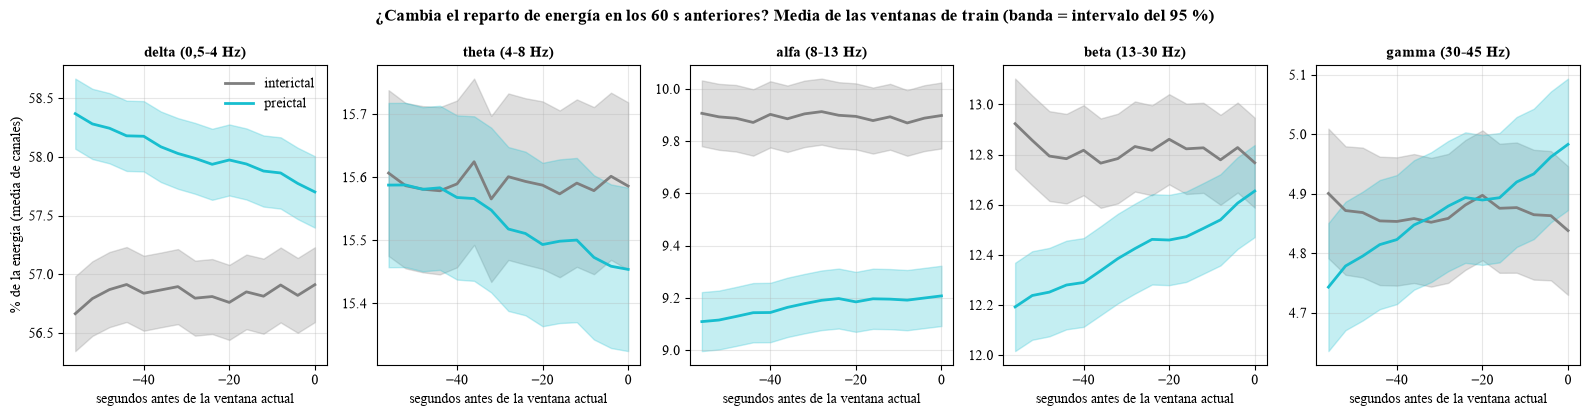

In [9]:
# 1) Resumir el contexto de cada ventana para cada duración (4 s = la ventana sola)
X_contexto = {}
for contexto in CONTEXTOS:
    k = ventanas_por_contexto(contexto, VENTANA_S)
    cubo = cubo_contexto(filas, k, MUESTRAS, claves_guardadas, valores)
    X_contexto[contexto] = cubo[:, -1, :] if k == 1 else resumir_contexto(cubo)
nombres_por_contexto = {c: NOMBRES if ventanas_por_contexto(c, VENTANA_S) == 1 else nombres_contexto(NOMBRES) for c in CONTEXTOS}

# 2) Tabla: cuántos números ve el modelo con cada contexto
display(con_separadores(pd.DataFrame({'ventanas de 4 s': [ventanas_por_contexto(c, VENTANA_S) for c in CONTEXTOS],
                                      'números por ventana': [X_contexto[c].shape[1] for c in CONTEXTOS]},
                                     index=pd.Index([f'{c} s' for c in CONTEXTOS], name='contexto')), decimales=0))

# 3) Figura: cómo evoluciona el reparto de energía en el último contexto, en ⏳ y en 💤 (🔵 train)
cubo_max = cubo_contexto(filas, K_MAX, MUESTRAS, claves_guardadas, valores)               # ventanas × K_MAX × 110
por_banda = np.nanmean(10 ** cubo_max.reshape(len(filas), K_MAX, len(CANALES_TCP), len(BANDAS)), axis=2) * 100   # % por banda
segundos = -VENTANA_S * np.arange(K_MAX - 1, -1, -1)                                       # inicio de cada ventana respecto a la actual
en_entrena = filas.en_entrenamiento.to_numpy(dtype=bool)

# 4) Dibujar un panel por banda
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(BANDAS), figsize=(16, 4.2), sharex=True)
    for b, (ax, banda) in enumerate(zip(axes, BANDAS)):
        for clase, etiqueta in [('interictal', 0), ('preictal', 1)]:
            datos = por_banda[en_entrena & (y == etiqueta), :, b]
            media = np.nanmean(datos, axis=0)
            error = 1.96 * np.nanstd(datos, axis=0) / np.sqrt(np.sum(~np.isnan(datos), axis=0))
            ax.plot(segundos, media, color=COLORES_PERIODO[clase], lw=2, label=clase)
            ax.fill_between(segundos, media - error, media + error, color=COLORES_PERIODO[clase], alpha=0.25)
        ax.set_title(f'{banda} ({numero_legible(BANDAS_HZ[banda][0])}-{numero_legible(BANDAS_HZ[banda][1])} Hz)', fontsize=11, fontweight='bold')
        ax.set_xlabel('segundos antes de la ventana actual')
        ax.grid(alpha=0.3)

    # 5) Rotular y guardar
    axes[0].set_ylabel('% de la energía (media de canales)')
    axes[0].legend(frameon=False)
    fig.suptitle(f'¿Cambia el reparto de energía en los {max(CONTEXTOS)} s anteriores? Media de las ventanas de train (banda = intervalo del 95 %)',
                 fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'evolucion_contexto.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por banda de frecuencia. Eje horizontal: segundos antes de la ventana actual (0 = ahora). Eje vertical: qué parte de la energía está en esa banda. Una línea para ⏳ y otra para 💤; la sombra es su margen de error.

✅ **Qué deberías ver:**
- Si las dos líneas van **separadas pero planas**, lo de antes es igual que lo de ahora: el contexto aporta poco.
- Si la línea ⏳ **sube o baja al acercarse al 0**, algo se está moviendo antes de la crisis: el contexto puede ayudar.

## 6. Cada paciente frente a sí mismo

> 🎯 **Qué hacemos:** a cada número de cada paciente le restamos **su valor normal**. Así el modelo ve *cuánto se aparta esta ventana de lo normal en esta persona*.
>
> 🤔 **Por qué:** cada persona tiene su propio nivel (su cerebro, sus electrodos, su medicación). Un mismo número puede ser alto en uno y normal en otro. F03.02 ya lo apuntaba: dentro de cada paciente el modelo ordenaba mejor (AUC ≈ 0,58) que mezclando a todos (≈ 0,51).

![Cada paciente frente a sí mismo](img/normalizacion_paciente.png)

👀 **Qué enseña.** A la izquierda, dos pacientes en niveles distintos: ningún umbral común separa sus ⏳ (rojo) de sus 💤 (blanco). A la derecha, restado a cada uno su valor normal, un mismo umbral sirve para los dos.

**La pregunta es: ¿de dónde sale "lo normal" de cada paciente?** Se prueban dos formas:

| Normalización | "Lo normal" de cada paciente sale de… |
|---|---|
| `por_paciente` | **todas** sus ventanas, sin mirar etiquetas |
| `por_paciente_reserva` | sus **primeros 2 minutos tranquilos** (💤), apartados solo para eso (§6.1) |

### 6.1 La calibración limpia (`por_paciente_reserva`)

![La calibración limpia, en tres pasos](img/calibracion_reserva.png)

👀 **Qué enseña.** (1) Se apartan las primeras 💤 de cada paciente. (2) Su mediana es "lo normal" en él. (3) A **todas** sus demás ventanas se les resta ese mismo valor, sean ⏳ o 💤.

> 💡 Se usa la **mediana** (el valor del medio) y no la media, para que un valor raro no lo mueva todo. Y se divide por lo que suele variar ese paciente, para que todos queden en la misma escala.

### 6.2 Por qué no se usa la versión anterior

La primera versión de este notebook (`por_paciente_calibrado`, ejecución del 6-nov) elegía **con qué comparar cada ventana según su etiqueta**: las 💤 con la otra mitad de sus 💤, y las ⏳ con todas.

![Por qué se cambió la calibración](img/fuga_calibracion.png)

👀 **Qué enseña.** El mismo paciente con las dos versiones. A la izquierda, ⏳ y 💤 del lunes valen lo mismo pero salen distintas (−4 y −2): una **pista falsa** que el modelo puede aprender. A la derecha, con una sola referencia, salen iguales.

> 🧪 En §9 se entrena también la versión antigua, para medir **cuánto inflaba la nota**.

### 6.3 En el código: tres pasos

➡️ **Paso 1.** Reservar las primeras 💤 de cada paciente (en el orden del tiempo) y ver cuántas ventanas quedan.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FS</code> · muestras por segundo (256) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RESERVA_CALIBRACION_S</code> · segundos de 💤 que se reservan por paciente para calibrar (120) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">VENTANA_S</code> · segundos por ventana (4) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MINIMO_RESERVA_S</code> · segundos mínimos de reserva para que un paciente se pueda calibrar (40) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [10]:
# 1) La reserva de calibración: por paciente, sus primeras 💤 en el tiempo (como los minutos tranquilos de una app)
es_tranquila = (y == 0)
segundo_en_fichero = inicio_tramo_s(filas.ruta) + filas.muestra_inicio.to_numpy() / FS
orden_tiempo = np.lexsort((segundo_en_fichero, filas.file.astype(str).to_numpy()))      # por fichero (sesión, t00X) y segundo
posicion_tiempo = np.empty(len(filas), dtype=np.int64)
posicion_tiempo[orden_tiempo] = np.arange(len(filas))
reservada, calibrable = reserva_calibracion(pacientes, es_tranquila, posicion_tiempo,
                                            n_reserva=ventanas_por_contexto(RESERVA_CALIBRACION_S, VENTANA_S),
                                            minimo=ventanas_por_contexto(MINIMO_RESERVA_S, VENTANA_S))

# 2) Las ventanas que se usan (en TODAS las normalizaciones, para comparar con las mismas): de pacientes calibrables y no reservadas
usar = calibrable & ~reservada

# 3) Tabla de la reserva por partición y clase
filas_reserva = {}
for (split, clase), t in filas.groupby(['split', 'clase'], sort=False):
    i = t.index.to_numpy()
    filas_reserva[(con_icono(split), con_icono(clase))] = {
        'ventanas': len(i), 'reservadas para calibrar': int(reservada[i].sum()),
        'de pacientes sin calibración (fuera)': int((~calibrable[i]).sum()), 'se usan': int(usar[i].sum()),
        'pacientes que se usan': filas.patient[i[usar[i]]].nunique()}
tabla_reserva = pd.DataFrame(filas_reserva).T
tabla_reserva.index.names = ['split', 'clase']
display(con_separadores(tabla_reserva, decimales=0))

👀 **Cómo leer la tabla.** Para cada partición y clase: cuántas ventanas hay, cuántas 💤 se reservan para calibrar, cuántas son de pacientes que no se pueden calibrar (les faltan 💤) y cuántas se usan al final. Solo las 💤 tienen reservadas.

✅ **Qué deberías ver:** que se usa la gran mayoría y que casi no se pierden pacientes. Ojo: desde aquí la línea base (4 s, sin normalizar) se mide con estas ventanas, así que puede salir un poco distinta de §3.


➡️ **Paso 2.** Desde aquí, entrenar y medir **solo** con las ventanas que se usan: sin las reservadas ni los pacientes sin calibración. Vale para las tres normalizaciones, también para la línea base, para que todas se comparen con las mismas ventanas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rondas</code> · con qué ventanas se entrena y con cuáles se mide <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · qué ventanas se examinan <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">usar</code> · ventanas que se usan: de pacientes con calibración y no reservadas <i style="color:#4d4d4d">(§6, paso 1)</i></li></ul></div>

In [11]:
# 1) Desde aquí, entrenar y medir solo con esas ventanas
rondas = [(nombre, entrena & usar, valida & usar) for nombre, entrena, valida in rondas]
validar = validar & usar
print(f'Desde aquí se entrena con {numero_legible(int(sum(e.sum() for _, e, _ in rondas)))} ventanas y se mide con {numero_legible(int(validar.sum()))} '
      f'(las mismas para las tres normalizaciones)')

Desde aquí se entrena con 23.368 ventanas y se mide con 48.829 (las mismas para las tres normalizaciones)


➡️ **Paso 3.** La función que aplica cada normalización. Se usa en §7 (y la versión antigua solo en el diagnóstico de §9).

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">reservada</code> · True en las 💤 reservadas para calibrar <i style="color:#4d4d4d">(§6, paso 1)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">es_tranquila</code> · True en las 💤 interictales (solo para la versión antigua) <i style="color:#4d4d4d">(§6, paso 1)</i></li></ul></div>

In [12]:
# 1) Cómo se prepara cada normalización
def preparar(X, normalizacion):
    if normalizacion == 'por_paciente':
        return normalizar_por_paciente(X, pacientes)
    if normalizacion == 'por_paciente_reserva':
        return normalizar_con_reserva(X, pacientes, reservada)
    if normalizacion == 'calibrado_antiguo':          # solo para el diagnóstico de §9 (la versión con fuga por la etiqueta)
        return normalizar_con_calibracion(X, pacientes, es_tranquila)
    return X

## 7. Medir en dev: cada contexto, con y sin normalización por paciente

> 🎯 **Qué hacemos:** entrenar los dos modelos de F03.02 con cada combinación (5 contextos × 3 normalizaciones) y ponerles nota en 🟡 dev.
>
> 🤔 **Por qué:** es el experimento en sí. Así vemos qué idea ayuda y cuánto.

![Las cuatro combinaciones que se prueban](img/cuatro_combinaciones.png)

👀 **Qué enseña.** El experimento en una tabla de 2 × 2: con o sin contexto, y con o sin comparar a cada paciente consigo mismo. La idea a comprobar es que solo la casilla roja (**las dos cosas juntas**) anuncia la crisis.

**Recordatorio: cómo se pone la nota (AUC).**

![La nota: AUC-ROC](img/auc_roc.png)

👀 **Qué enseña.** El modelo da a cada ventana una puntuación. Se ordenan: si las ⏳ (rojas) quedan a la derecha de las 💤 (blancas), el modelo es bueno. **0,5 = mezcladas (azar)**, 1 = perfecto. Abajo, por qué también se mira la nota **dentro de cada paciente**.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACIONES</code> · las tres formas de normalizar que se prueban: ninguna, por paciente y por paciente con reserva <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODELOS</code> · modelo → (variante, hiperparámetros), los de F03.02 <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rondas</code> · lista de (nombre, entrena, valida): qué ventanas entrenan y cuáles se miden <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X_contexto</code> · contexto (s) → matriz ventanas × números que ve el modelo con ese contexto <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code> · especificidad fija para dar la sensibilidad (0,9) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [13]:
# 1) Entrenar cada modelo × normalización × contexto y medirlo en dev
filas_res, puntuaciones = {}, {}
inicio = time.time()
for nombre, (variante, hp) in MODELOS.items():
    for normalizacion in NORMALIZACIONES:
        for contexto in CONTEXTOS:
            X = preparar(X_contexto[contexto], normalizacion)
            p = np.full(len(filas), np.nan)
            for _, entrena, valida in rondas:
                modelo = entrenar(nombre, hp, X[entrena], y[entrena], pacientes[entrena], variante, SEMILLA)
                p[valida] = puntuar(modelo, X[valida])
            puntuaciones[(nombre, normalizacion, contexto)] = p
            auc, inferior, superior = auroc_con_intervalo(y[validar], p[validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
            pp = auroc_por_paciente(y[validar], p[validar], pacientes[validar])
            filas_res[(NOMBRES_MODELO[nombre], normalizacion, contexto)] = {
                'AUC-ROC': auc, 'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}',
                f'sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %': sensibilidad_con_especificidad(y[validar], p[validar], ESPECIFICIDAD)[0],
                'AUC por paciente (mediana)': float(pp.auroc.median()) if len(pp) else np.nan,
                '_inferior': inferior, '_superior': superior}

# 2) Tabla de resultados, ordenada por modelo, normalización y contexto
resultados = pd.DataFrame(filas_res).T.infer_objects()
resultados.index.names = ['modelo', 'normalización', 'contexto (s)']
resultados = resultados.sort_index()   # ordenado por modelo, normalización y contexto (de menos a más segundos)
display(con_separadores(resultados.drop(columns=['_inferior', '_superior']), decimales=3))
print(f'{len(resultados)} entrenamientos en {numero_legible(round((time.time() - inicio) / 60, 1))} min')

30 entrenamientos en 5,5 min


👀 **Cómo leer la tabla.** Una fila por modelo, normalización y contexto. La fila **4 s, `ninguna`** es la línea base de F03.02 (con estas ventanas). Columnas: la nota (AUC) con su margen de error, cuántas ⏳ detecta si solo se permite fallar en el 10 % de las 💤, y la nota mediana **dentro** de cada paciente.

✅ **Qué deberías ver:** si el contexto ayuda, la AUC **sube** al bajar dentro de cada bloque (más segundos). Si normalizar ayuda, los bloques `por_paciente…` quedan **por encima** de `ninguna`. La figura de abajo lo enseña de un vistazo.

![Cómo leer la figura principal](img/como_leer_auc_contexto.png)

👀 **Antes de ver la figura de abajo.** Las tres formas que puede tener cada línea. Lo convincente es una **subida ordenada**, con su sombra por encima del 0,5. Un pico suelto suele ser casualidad.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODELOS</code> · modelo → (variante, hiperparámetros), los de F03.02 <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NORMALIZACIONES</code> · las tres formas de normalizar que se prueban: ninguna, por paciente y por paciente con reserva <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta donde se guardan las figuras <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · tabla con la nota en dev de cada modelo × normalización × contexto <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

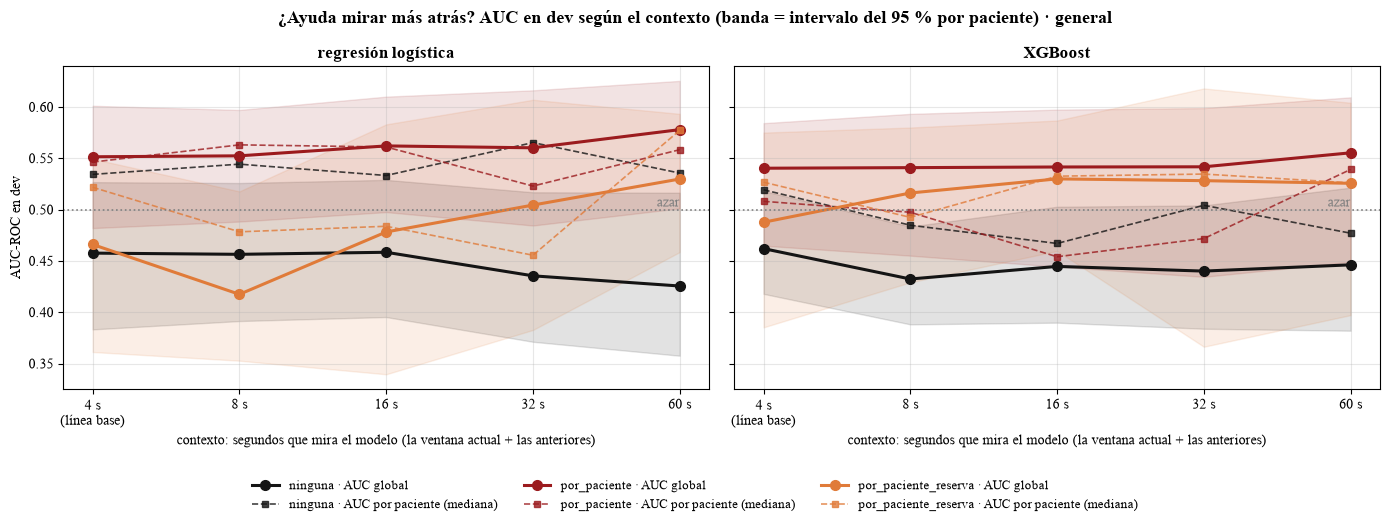

In [14]:
# 1) Figura principal: AUC en dev según el contexto, para cada modelo y normalización
COLOR_NORMALIZACION = {'ninguna': COLORES_ESQUEMA['negro'], 'por_paciente': COLORES_ESQUEMA['rojo'], 'por_paciente_reserva': '#e07b39'}

# 2) Dibujar un panel por modelo
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(MODELOS), figsize=(14, 5.2), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, MODELOS):
        for normalizacion in NORMALIZACIONES:
            t = resultados.loc[(NOMBRES_MODELO[nombre], normalizacion)]
            x = np.arange(len(CONTEXTOS))
            color = COLOR_NORMALIZACION[normalizacion]
            ax.plot(x, t['AUC-ROC'], 'o-', color=color, lw=2.2, ms=7, label=f'{normalizacion} · AUC global')
            ax.fill_between(x, t['_inferior'], t['_superior'], color=color, alpha=0.12)
            ax.plot(x, t['AUC por paciente (mediana)'], 's--', color=color, lw=1.2, ms=5, alpha=0.8, label=f'{normalizacion} · AUC por paciente (mediana)')
        ax.axhline(0.5, color='gray', ls=':', lw=1.2)
        ax.text(len(CONTEXTOS) - 1, 0.5, ' azar', color='gray', va='bottom', ha='right', fontsize=10)
        ax.set_xticks(range(len(CONTEXTOS)), [f'{c} s' + ('\n(línea base)' if c == min(CONTEXTOS) else '') for c in CONTEXTOS])
        ax.set_xlabel('contexto: segundos que mira el modelo (la ventana actual + las anteriores)')
        ax.set_title(NOMBRES_MODELO[nombre], fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)

    # 3) Rotular y guardar
    axes[0].set_ylabel('AUC-ROC en dev')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9.5, frameon=False)
    fig.suptitle(f'¿Ayuda mirar más atrás? AUC en dev según el contexto (banda = intervalo del 95 % por paciente) · {CONJUNTO}',
                 fontsize=13, fontweight='bold')
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    fig.savefig(RUTA_FIGURAS / 'auc_segun_contexto.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por modelo. Eje horizontal: cuántos segundos mira el modelo (4 s = la línea base). Colores: **negro** = sin normalizar; **rojo** = frente a todas sus ventanas; **naranja** = frente a sus primeros minutos tranquilos (calibración limpia). Línea continua = la nota global (con su sombra de margen de error); discontinua = la nota mediana **dentro** de cada paciente. La línea de puntos es el azar.

✅ **Qué deberías ver:** alguna línea que **suba** y cuya sombra quede **por encima del 0,5**. Si todo se queda plano en 0,5, ni el contexto ni la normalización bastan con estos modelos.

## 8. Por tipo de crisis: ¿cuánto contexto le va a cada uno?

> 🎯 **Qué hacemos:** con el mejor modelo de §7, repetir la nota **separando por grupo de crisis** (♦️ focal, 🔷 generalizada, 🔹 ausencia).
>
> 🤔 **Por qué:** cada tipo de crisis podría avisar de forma distinta. Las 🔹 ausencias aparecen de golpe (contexto corto); las ♦️ focales y 🔷 generalizadas podrían prepararse más despacio (contexto largo). Aquí se comprueba con datos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · tabla con la nota en dev de cada modelo × normalización × contexto <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · (modelo, normalización, contexto) → puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta donde se guardan las figuras <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li></ul></div>

**AUC en dev por grupo y contexto** (regresión logística, normalización por_paciente)

,4 s,8 s,16 s,32 s,60 s,mejor contexto,pacientes con ⏳
grupo de inicio,,,,,,,
♦️ focal,"0,537","0,546","0,559","0,558","0,577",60 s,19
🔷 generalizada,"0,592","0,575","0,576","0,572","0,581",4 s,15
🔹 ausencia,"0,470","0,431","0,452","0,471","0,576",60 s,2


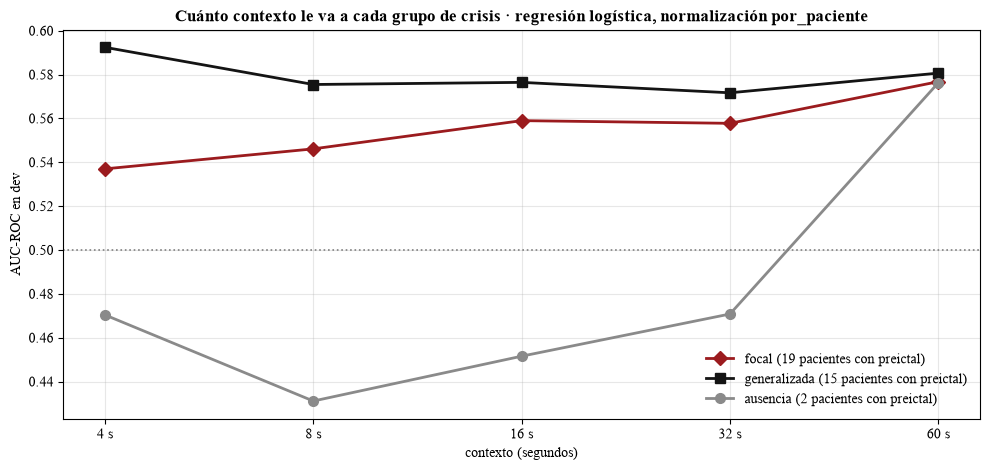

In [15]:
# 1) La mejor combinación de §7
mejor = resultados['AUC-ROC'].idxmax()                            # (modelo, normalización, contexto)
nombre_mejor = next(n for n, bonito in NOMBRES_MODELO.items() if bonito == mejor[0])

# 2) Su AUC en cada grupo de crisis y contexto (⏳ del grupo frente a todas las 💤)
grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[validar & (y == 1)].dropna())]
filas_grupo = {}
for grupo in grupos:
    mascara = validar & ((y == 0) | (filas.grupo.to_numpy() == grupo))
    for contexto in CONTEXTOS:
        p = puntuaciones[(nombre_mejor, mejor[1], contexto)]
        auc, inferior, superior = auroc_con_intervalo(y[mascara], p[mascara], pacientes[mascara], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        filas_grupo[(con_icono(grupo), contexto)] = {'AUC-ROC': auc, 'IC 95 %': f'{decimal(inferior)} – {decimal(superior)}',
                                                     'pacientes con ⏳': len(set(pacientes[mascara & (y == 1)]))}
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.names = ['grupo de inicio', 'contexto (s)']

# 3) Tabla y figura
if len(por_grupo):
    tabla_grupo = por_grupo['AUC-ROC'].unstack('contexto (s)')
    tabla_grupo.columns = [f'{c} s' for c in tabla_grupo.columns]
    tabla_grupo['mejor contexto'] = [f'{CONTEXTOS[int(np.nanargmax(v))]} s' for v in tabla_grupo.to_numpy(dtype=float)]
    tabla_grupo['pacientes con ⏳'] = por_grupo.groupby(level=0, sort=False)['pacientes con ⏳'].first()
    display(Markdown(f'**AUC en dev por grupo y contexto** ({mejor[0]}, normalización {mejor[1]})'))
    display(con_separadores(tabla_grupo, decimales=3))

    # Figura: una línea por grupo
    marcadores = {'♦️ focal': 'D', '🔷 generalizada': 's', '🔹 ausencia': 'o'}
    with plt.rc_context(ESTILO_TIMES):
        fig, ax = plt.subplots(figsize=(10, 4.8))
        for (grupo, t), color in zip(por_grupo.groupby(level=0, sort=False), [COLORES_ESQUEMA['rojo'], COLORES_ESQUEMA['negro'], COLORES_ESQUEMA['gris']]):
            nombre_limpio = grupo.split(' ', 1)[-1]
            ax.plot(range(len(CONTEXTOS)), t['AUC-ROC'].to_numpy(), marker=marcadores.get(grupo, 'o'), color=color, lw=2, ms=7,
                    label=f'{nombre_limpio} ({int(t["pacientes con ⏳"].iloc[0])} pacientes con preictal)')
        ax.axhline(0.5, color='gray', ls=':', lw=1.2)
        ax.set_xticks(range(len(CONTEXTOS)), [f'{c} s' for c in CONTEXTOS])
        ax.set_xlabel('contexto (segundos)')
        ax.set_ylabel('AUC-ROC en dev')
        ax.set_title(f'Cuánto contexto le va a cada grupo de crisis · {mejor[0]}, normalización {mejor[1]}', fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(frameon=False)
        fig.tight_layout()
        fig.savefig(RUTA_FIGURAS / 'auc_por_grupo_y_contexto.png', dpi=150, bbox_inches='tight')
        plt.show()
else:
    print('🟡 Las ventanas de validación no traen el grupo de inicio: no se puede separar por grupo.')

👀 **Cómo leer la tabla y la figura.** Una fila (y una línea) por grupo de crisis; una columna por contexto. *Mejor contexto* dice con cuántos segundos sale la mejor nota para ese grupo.

✅ **Qué deberías ver:** si la idea se cumple, las 🔹 ausencias tendrán su mejor nota con contextos cortos y las ♦️ / 🔷 con contextos largos.

⚠️ **Cuidado:** un grupo con **pocos pacientes** da cifras poco fiables (un salto entre columnas puede ser ruido). La cifra seria de las ausencias sale del conjunto `grupo_ausencia`.

## 9. Decidir: ¿qué se lleva la red?

> 🎯 **Qué hacemos:** comparar la mejor combinación con la línea base (4 s, sin normalizar), de forma **emparejada**.
>
> 🤔 **Por qué:** que una nota sea más alta no basta; puede ser suerte. La comparación emparejada dice si la mejora es **real**.

![Comparar dos modelos de forma emparejada](img/comparacion_emparejada.png)

👀 **Qué enseña.** A la izquierda, mirar dos márgenes de error por separado: se solapan y no se puede decir nada. A la derecha, medir los dos modelos con **los mismos pacientes** y restar: la suerte afecta igual a los dos y se cancela. **Regla:** si el margen de la resta **no toca el 0**, la mejora es real.

Además, aunque sea real, si la mejora es menor que `MEJORA_MINIMA` (0,02) no compensa complicar la red.

Se hace en cuatro pasos: **(1)** la comparación, **(2)** la prueba de robustez, **(3)** el diagnóstico de la calibración antigua y **(4)** la decisión.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code> · el nombre interno del modelo de la mejor combinación <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora de AUC por debajo de la cual no compensa (0,02) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · tabla con la nota en dev de cada modelo × normalización × contexto <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · (modelo, normalización, contexto) → puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§7)</i></li></ul></div>

In [16]:
# 1) La mejor combinación frente a la línea base (4 s, sin normalizar), emparejadas
base = (nombre_mejor, 'ninguna', min(CONTEXTOS))
diferencia, dif_inf, dif_sup = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, mejor[1], mejor[2])][validar],
                                                              puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

# 2) Lo mismo separando las dos palancas: solo contexto (sin normalizar) y solo normalización (4 s)
mejor_ctx = resultados.loc[(mejor[0], 'ninguna'), 'AUC-ROC'].idxmax()
solo_contexto = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, 'ninguna', mejor_ctx)][validar],
                                               puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
solo_paciente = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, 'por_paciente', min(CONTEXTOS))][validar],
                                               puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

# 3) Tabla de la comparación
comparacion = pd.DataFrame({
    'qué se compara con la línea base (4 s, sin normalizar)': [f'solo contexto ({mejor_ctx} s)', 'solo normalización por paciente (4 s)',
                                                                f'la mejor combinación ({mejor[2]} s, {mejor[1]})'],
    'diferencia de AUC': [con_signo(d) for d in [solo_contexto[0], solo_paciente[0], diferencia]],
    'IC 95 % de la diferencia': [f'{decimal(a, 3)} – {decimal(b, 3)}' for _, a, b in [solo_contexto, solo_paciente, (diferencia, dif_inf, dif_sup)]],
    '¿real? (el IC no incluye el 0)': ['sí' if a > 0 or b < 0 else 'no' for _, a, b in [solo_contexto, solo_paciente, (diferencia, dif_inf, dif_sup)]],
}).set_index('qué se compara con la línea base (4 s, sin normalizar)')

# 4) ¿La mejora es real y compensa?
mejora_clara = dif_inf > 0 and diferencia >= MEJORA_MINIMA
auc_mejor, inf_mejor, sup_mejor = resultados.loc[mejor, ['AUC-ROC', '_inferior', '_superior']]

➡️ **Paso 2 · Prueba de robustez.** Si la mejor combinación usa `por_paciente`, se repite con la calibración limpia (`por_paciente_reserva`). Si la nota aguanta, la mejora no depende de cómo se calcula "lo normal".

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code> · el nombre interno del modelo de la mejor combinación <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · (modelo, normalización, contexto) → puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">base</code> · la línea base: (modelo, ninguna, 4 s) <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · tabla con la nota en dev de cada modelo × normalización × contexto <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion</code> · tabla de la comparación emparejada con la línea base <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_mejor</code> · AUC de la mejor combinación <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora de AUC por debajo de la cual no compensa (0,02) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [17]:
# 1) La misma combinación (modelo y contexto), con la calibración limpia (reserva de 💤)
calibrada = (nombre_mejor, 'por_paciente_reserva', mejor[2])
robustez = diferencia_auroc_con_intervalo(y[validar], puntuaciones[calibrada][validar], puntuaciones[base][validar], pacientes[validar],
                                          n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
auc_calibrada = float(resultados.loc[(mejor[0], 'por_paciente_reserva', mejor[2]), 'AUC-ROC'])

# 2) El veredicto de robustez
if mejor[1] == 'ninguna':
    robusto, texto_robustez = True, 'La mejor combinación no normaliza por paciente: la prueba de robustez no hace falta.'
elif mejor[1] == 'por_paciente_reserva':
    robusto, texto_robustez = True, ('La mejor combinación ya usa la <b>calibración limpia</b> (reserva de 💤 y la misma referencia para ⏳ y 💤): '
                                     'es la versión estricta, así que no hace falta otra prueba.')
else:
    robusto = robustez[1] > 0 and auc_calibrada >= auc_mejor - MEJORA_MINIMA
    texto_robustez = (f'Con la calibración limpia (reserva de 💤), la misma combinación da AUC <b>{decimal(auc_calibrada)}</b> '
                      f'({con_signo(robustez[0])} sobre la línea base; IC {decimal(robustez[1], 3)} – {decimal(robustez[2], 3)}). '
                      + ('<b>✅ Se mantiene: la mejora es robusta</b>, no viene de cómo se calcula la mediana.' if robusto else
                         ('🟡 Sigue mejorando a la línea base, pero bastante menos: parte de la mejora venía de la forma de calibrar.' if robustez[1] > 0 else
                          '🔴 <b>Se cae</b>: con la calibración limpia no hay mejora segura. La mejora de antes dependía de cómo se calcula la mediana.')))
    comparacion.loc[f'robustez: la misma, con calibración limpia ({mejor[2]} s, reserva de 💤)'] = [
        con_signo(robustez[0]), f'{decimal(robustez[1], 3)} – {decimal(robustez[2], 3)}', 'sí' if robustez[1] > 0 or robustez[2] < 0 else 'no']

➡️ **Paso 3 · Diagnóstico de la versión antigua.** Se entrena también la calibración antigua (la que tenía la fuga, §6.2) con el mismo modelo y las mismas ventanas. La diferencia con la limpia es **lo que inflaba la nota la fuga**. Solo se mide para contarlo; no se usa para decidir.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rondas</code> · lista de (nombre, entrena, valida): qué ventanas entrenan y cuáles se miden <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · (modelo, normalización, contexto) → puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X_contexto</code> · contexto (s) → matriz ventanas × números que ve el modelo con ese contexto <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code> · el nombre interno del modelo de la mejor combinación <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion</code> · tabla de la comparación emparejada con la línea base <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">calibrada</code> · la misma combinación, con la calibración limpia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODELOS</code> · modelo → (variante, hiperparámetros), los de F03.02 <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_calibrada</code> · AUC con la calibración limpia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados</code> · tabla con la nota en dev de cada modelo × normalización × contexto <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [18]:
# 1) La calibración ANTIGUA (referencia según la etiqueta), con el mismo modelo, contexto y ventanas
X_antigua = preparar(X_contexto[mejor[2]], 'calibrado_antiguo')
p_antigua = np.full(len(filas), np.nan)
for _, entrena, valida in rondas:
    modelo = entrenar(nombre_mejor, MODELOS[nombre_mejor][1], X_antigua[entrena], y[entrena], pacientes[entrena], MODELOS[nombre_mejor][0], SEMILLA)
    p_antigua[valida] = puntuar(modelo, X_antigua[valida])
puntuaciones[(nombre_mejor, 'calibrado_antiguo', mejor[2])] = p_antigua

# 2) Su nota y su diferencia con la limpia
auc_antigua = auroc_con_intervalo(y[validar], p_antigua[validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
antigua_frente_limpia = diferencia_auroc_con_intervalo(y[validar], p_antigua[validar], puntuaciones[calibrada][validar], pacientes[validar],
                                                       n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
comparacion.loc[f'diagnóstico: calibración antigua, con fuga por la etiqueta ({mejor[2]} s)'] = [
    con_signo(auc_antigua[0] - float(resultados.loc[(mejor[0], 'ninguna', min(CONTEXTOS)), 'AUC-ROC'])), '—', 'no se usa (con fuga)']

# 3) El texto del diagnóstico
texto_antigua = (f'<b>Diagnóstico de la calibración antigua</b> (la de la ejecución del 6-nov, que elegía la referencia según la etiqueta): '
                 f'con {mejor[2]} s da AUC <b>{decimal(auc_antigua[0])}</b>, frente a <b>{decimal(auc_calibrada)}</b> con la limpia '
                 f'(diferencia {con_signo(antigua_frente_limpia[0])}; IC {decimal(antigua_frente_limpia[1], 3)} – {decimal(antigua_frente_limpia[2], 3)}). '
                 + ('🔴 La antigua inflaba la nota de forma clara: esa parte no era predicción.' if antigua_frente_limpia[1] > 0 else
                    '✅ No hay una diferencia segura: la fuga casi no influía en estos datos.'))

➡️ **Paso 4 · La decisión.** Todo lo anterior en un recuadro dorado, con lo que se lleva la red.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejora_clara</code> · <code>True</code> si la mejora es real y compensa <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">texto_robustez</code> · el texto de la prueba de robustez <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">texto_antigua</code> · el texto del diagnóstico de la calibración antigua <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion</code> · tabla de la comparación emparejada con la línea base <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">robusto</code> · <code>True</code> si la mejora aguanta la calibración limpia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONTEXTOS</code> · los contextos que se prueban, en segundos (4, 8, 16, 32, 60 en el modelo general) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_mejor</code> · AUC de la mejor combinación <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">inf_mejor</code> · límite inferior de su intervalo <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">sup_mejor</code> · límite superior de su intervalo <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">diferencia</code> · cuánto mejora la mejor combinación a la línea base <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dif_inf</code> · límite inferior del intervalo de esa diferencia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dif_sup</code> · límite superior del intervalo de esa diferencia <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora de AUC por debajo de la cual no compensa (0,02) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [19]:
# 1) La decisión: qué contexto y normalización recibe la red
if mejora_clara:
    decision = (f'La red recibirá {mejor[2]} s de contexto' + (' y cada paciente normalizado frente a sí mismo' if mejor[1] != 'ninguna' else '')
                + ('' if robusto else ' (🟡 robustez por confirmar)'),
                f'<b>{mejor[0]}</b> con <b>{mejor[2]} s</b> de contexto y normalización <b>{mejor[1]}</b> → AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}. '
                f'Mejora a la línea base en <b>{con_signo(diferencia)}</b> (IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)}): es real y compensa.')
    contexto_red, normalizacion_red = int(mejor[2]), (mejor[1] if robusto or mejor[1] == 'ninguna' else 'por_paciente_reserva')
else:
    decision = ('Ninguna palanca mejora de forma clara',
                f'La mejor combinación ({mejor[0]}, {mejor[2]} s, {mejor[1]}) da AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}, '
                f'{con_signo(diferencia)} sobre la línea base (IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)}): '
                + ('no es una mejora segura.' if dif_inf <= 0 else f'real, pero menor que {decimal(MEJORA_MINIMA)}.')
                + ' La red empezará con la ventana sola y probará el contexto como experimento.')
    contexto_red, normalizacion_red = int(min(CONTEXTOS)), 'ninguna'

# 2) Mostrarlo todo en un recuadro
mostrar_destacado(f'Decisión para la red (F03.04) · {decision[0]}', decision[1], texto_robustez, texto_antigua, con_separadores(comparacion, decimales=3))

,diferencia de AUC,IC 95 % de la diferencia,¿real? (el IC no incluye el 0)
"qué se compara con la línea base (4 s, sin normalizar)",,,
solo contexto (16 s),"+0,001","-0,016 – 0,024",no
solo normalización por paciente (4 s),"+0,094","0,000 – 0,145",sí
"la mejor combinación (60 s, por_paciente)","+0,120","0,003 – 0,185",sí
"robustez: la misma, con calibración limpia (60 s, reserva de 💤)","+0,072","-0,019 – 0,127",no
"diagnóstico: calibración antigua, con fuga por la etiqueta (60 s)","+0,135",—,no se usa (con fuga)


👀 **Cómo leer el recuadro.**
- **Arriba:** la decisión para la red.
- **Párrafos:** si la mejora aguanta la prueba de robustez y cuánto inflaba la nota la versión antigua.
- **Tabla:** cada comparación con la línea base. *Diferencia de AUC* = cuánto mejora; *IC 95 %* = su margen de error; *¿real?* = **sí** si el margen no toca el 0.

✅ **Qué deberías ver:** cuál de las dos ideas aporta más, y si juntas mejoran de verdad. Si ninguna mejora, también es un resultado útil para la memoria: con estos modelos, mirar atrás y calibrar por paciente no bastan.

## 10. Control de sesión: ¿predice la crisis o reconoce la grabación?

> 🎯 **Qué hacemos:** repetir la nota quitando una **trampa** posible: comparar ⏳ y 💤 de **grabaciones distintas**.
>
> 🤔 **Por qué:** las ⏳ salen siempre de la grabación donde hubo crisis. Muchas 💤 salen de **otros días** (otros electrodos, otro estado del paciente). El modelo podría aprender *"esta grabación es distinta"* en vez de *"se acerca una crisis"*. Es como un detector de mentiras que en realidad detecta si la habitación es otra. F02.05 ya vio que esta pista existe.

![El control de sesión](img/control_sesion_esquema.png)

👀 **Qué enseña.** Un paciente con tres grabaciones; solo la del lunes tiene crisis. Si comparamos las ⏳ del lunes con 💤 del martes y del jueves, el modelo puede acertar solo porque **son días distintos**. El control *misma sesión* usa solo 💤 del lunes: la trampa desaparece.

**Los tres controles** (las ⏳ son siempre las mismas; cambian las 💤 con las que se comparan):

| Control | Con qué 💤 se compara | Qué trampa quita |
|---|---|---|
| todas las 💤 | todas las de 🟡 dev (lo de §7) | ninguna |
| misma sesión | solo las del **mismo día** de grabación que las ⏳ de ese paciente | la diferencia entre días |
| mismo fichero | solo las del **mismo fichero** | también la diferencia entre ficheros. Ojo: aquí muchas 💤 son de **después** de la crisis, así que es un control muy duro |

No se reentrena nada: se usan los modelos de §7. Si la mejora es predicción de verdad, debe **mantenerse** en *misma sesión*.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · <code>True</code> en las ventanas que se miden (🟡 dev) <i style="color:#4d4d4d">(§3, recortadas en §6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code> · el nombre interno del modelo de la mejor combinación <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">base</code> · la línea base: (modelo, ninguna, 4 s) <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · sorteos de pacientes para los intervalos (500) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana estudiada (con contexto completo): quién es, clase, partición, grupo… <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · (modelo, normalización, contexto) → puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§7)</i></li></ul></div>

In [20]:
# 1) Sesión y fichero de cada ventana
sesion = filas.file.astype(str).str.extract(r'^(.*?_s\d+)')[0].fillna(filas.file.astype(str)).to_numpy()
fichero = filas.file.astype(str).to_numpy()

# 2) Máscara de un control: ⏳ de validación + 💤 de los grupos (sesión o fichero) en los que su paciente tiene alguna ⏳
def mascara_control(grupo):
    # ⏳ de validación + solo las 💤 de validación de los grupos (sesión o fichero) en los que su paciente tiene alguna ⏳
    con_preictal = set(zip(pacientes[validar & (y == 1)], grupo[validar & (y == 1)]))
    mismo = np.fromiter(((p, g) in con_preictal for p, g in zip(pacientes, grupo)), dtype=bool, count=len(filas))
    return validar & ((y == 1) | ((y == 0) & mismo))

# 3) Los tres controles, con la nota de la línea base y de la mejor combinación en cada uno
controles_dev = {'todas las 💤': validar, 'misma sesión': mascara_control(sesion), 'mismo fichero': mascara_control(fichero)}
clave_mejor = (nombre_mejor, mejor[1], mejor[2])
filas_control, notas_control = {}, {}
for nombre_control, m in controles_dev.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    pac_dos = {p for p in set(pacientes[m]) if len(set(y[m & (pacientes == p)])) == 2}
    fila = {'pacientes con las dos clases': len(pac_dos), '⏳ preictal': int((y[m] == 1).sum()), '💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, clave_m in [('línea base', base), ('mejor', clave_mejor)]:
        a, i_, s_ = auroc_con_intervalo(y[m], puntuaciones[clave_m][m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'] = a
        fila[f'IC {etiqueta}'] = f'{decimal(i_)} – {decimal(s_)}'
        notas_control[(nombre_control, etiqueta)] = (a, i_, s_)
    d = diferencia_auroc_con_intervalo(y[m], puntuaciones[clave_mejor][m], puntuaciones[base][m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    fila['mejora (mejor − línea base)'] = con_signo(d[0])
    fila['IC de la mejora'] = f'{decimal(d[1], 3)} – {decimal(d[2], 3)}'
    notas_control[(nombre_control, 'diferencia')] = d
    filas_control[nombre_control] = fila

# 4) Tabla
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'

➡️ **El veredicto**, con el control de *misma sesión* (el que importa).

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas_control</code> · control → su fila de la tabla del control de sesión <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_control</code> · (control, modelo) → AUC e intervalo en ese control <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code> · tabla del control de sesión <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_mejor</code> · AUC de la mejor combinación <i style="color:#4d4d4d">(§9)</i></li></ul></div>

In [21]:
# 1) Veredicto con el control de misma sesión (el más importante): ¿se mantiene la mejora?
if 'misma sesión' in filas_control:
    auc_ses, inf_ses, _ = notas_control[('misma sesión', 'mejor')]
    dif_ses = notas_control[('misma sesión', 'diferencia')]
    if dif_ses[1] > 0 and auc_ses >= auc_mejor - 0.05:
        veredicto_sesion = ('✅ Se mantiene: predice la crisis, no la grabación',
                            f'Con solo 💤 de las mismas sesiones, la mejor combinación da <b>AUC {decimal(auc_ses)}</b> (en §7: {decimal(auc_mejor)}) '
                            f'y sigue mejorando a la línea base en <b>{con_signo(dif_ses[0])}</b> (IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}).')
    elif dif_ses[1] > 0:
        veredicto_sesion = ('🟡 Se mantiene en parte',
                            f'Con solo 💤 de las mismas sesiones baja a <b>AUC {decimal(auc_ses)}</b> (en §7: {decimal(auc_mejor)}), aunque sigue mejorando a la '
                            f'línea base ({con_signo(dif_ses[0])}; IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}). Parte de la mejora venía de reconocer la grabación.')
    else:
        veredicto_sesion = ('🔴 Se cae: reconocía la grabación',
                            f'Con solo 💤 de las mismas sesiones, la mejora desaparece (AUC {decimal(auc_ses)}; {con_signo(dif_ses[0])}, '
                            f'IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}). La red tendrá que entrenarse y medirse con este control desde el principio.')
else:
    veredicto_sesion = ('🟡 Sin control de sesión', 'En dev no hay 💤 de las mismas sesiones que las ⏳: no se puede hacer este control.')

# 2) Mostrarlo
mostrar_destacado(f'Control de sesión · {veredicto_sesion[0]}', veredicto_sesion[1], con_separadores(control_sesion, decimales=3))

# 3) Aviso si el control de mismo fichero sube demasiado
if 'mismo fichero' in filas_control and notas_control[('mismo fichero', 'mejor')][0] > auc_mejor + 0.05:
    display(Markdown(f'🟡 **Ojo con *mismo fichero*:** sube a AUC {decimal(notas_control[("mismo fichero", "mejor")][0])}, por encima de §7. '
                     'En ese control casi todas las 💤 son de **después** de la crisis (F02.05), así que el modelo podría estar distinguiendo también '
                     '"antes" de "después" de una crisis. No invalida el resultado (el control importante es el de la sesión), pero hay que vigilarlo '
                     'con la red y contarlo en la memoria.'))

,pacientes con las dos clases,⏳ preictal,💤 interictal,AUC línea base,IC línea base,AUC mejor,IC mejor,mejora (mejor − línea base),IC de la mejora
qué 💤 se usan,,,,,,,,,
todas las 💤,28,7.519,41.310,"0,46","0,38 – 0,53","0,58","0,50 – 0,63","+0,120","0,003 – 0,185"
misma sesión,25,7.519,7.312,"0,45","0,37 – 0,55","0,54","0,46 – 0,59","+0,083","-0,035 – 0,153"
mismo fichero,18,7.519,1.020,"0,37","0,28 – 0,48","0,43","0,30 – 0,55","+0,059","-0,084 – 0,162"


➡️ **La figura:** la línea base y la mejor combinación en cada control.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas_control</code> · control → su fila de la tabla del control de sesión <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta donde se guardan las figuras <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_control</code> · (control, modelo) → AUC e intervalo en ese control <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor</code> · la mejor combinación: (modelo, normalización, contexto) <i style="color:#4d4d4d">(§8)</i></li></ul></div>

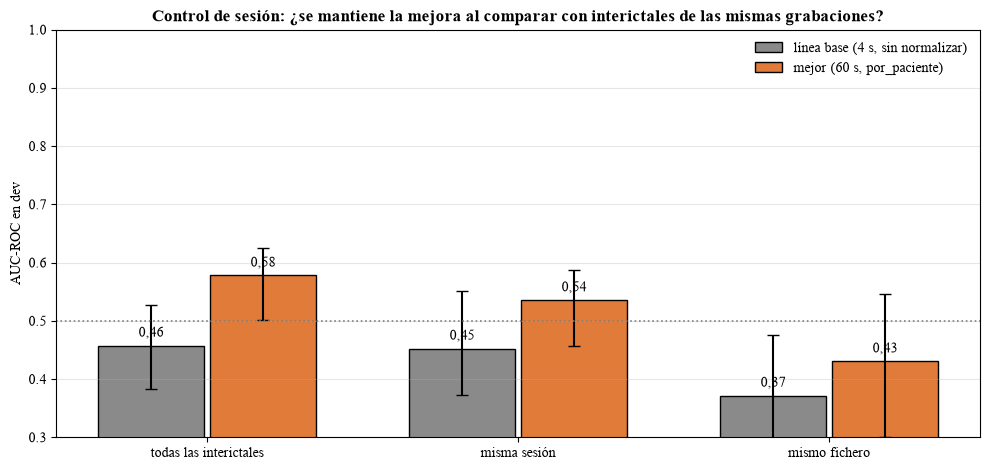

In [22]:
# 1) Figura: AUC de la línea base y de la mejor combinación en cada control
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    nombres_c = list(filas_control)
    for k, (etiqueta, color) in enumerate([('línea base', COLORES_ESQUEMA['gris']), ('mejor', '#e07b39')]):
        valores_c = np.array([notas_control[(c, etiqueta)] for c in nombres_c])
        x = np.arange(len(nombres_c)) + (k - 0.5) * 0.36
        ax.bar(x, valores_c[:, 0], width=0.34, color=color, edgecolor='black',
               label='línea base (4 s, sin normalizar)' if etiqueta == 'línea base' else f'mejor ({mejor[2]} s, {mejor[1]})')
        ax.errorbar(x, valores_c[:, 0], yerr=[valores_c[:, 0] - valores_c[:, 1], valores_c[:, 2] - valores_c[:, 0]], fmt='none', ecolor='black', capsize=4)
        for xi, v in zip(x, valores_c[:, 0]):
            ax.text(xi, v + 0.01, decimal(v), ha='center', va='bottom', fontsize=10)

    # 2) Rotular y guardar
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_xticks(range(len(nombres_c)), [c.replace('💤', 'interictales') for c in nombres_c])
    ax.set_ylabel('AUC-ROC en dev')
    ax.set_ylim(0.3, 1)
    ax.set_title('Control de sesión: ¿se mantiene la mejora al comparar con interictales de las mismas grabaciones?', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, loc='upper right')
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'control_sesion.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer el recuadro y la figura.** Una fila (y una pareja de barras) por control: la nota de la línea base (gris), la de la mejor combinación (naranja) y cuánto mejora una sobre otra, con su margen de error. El veredicto usa *misma sesión*:

- ✅ la nota se mantiene cerca de la de §7 y sigue mejorando a la línea base → **predice la crisis**;
- 🟡 sigue mejorando, pero baja bastante → parte de la mejora era reconocer la grabación;
- 🔴 la mejora desaparece → el modelo **reconocía la grabación**.

✅ **Qué deberías ver:** la barra naranja por encima de la gris también en *misma sesión*. En *mismo fichero* es normal que cambie mucho: es un control muy duro y quedan pocos pacientes.

## 11. Guardar los resultados → tablas y `configuracion.json`

> 🎯 **Qué hacemos:** guardar en disco las tablas de resultados y la **decisión para la red** (`configuracion.json`), para que F03.04 la lea sola.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados, puntuaciones</code> · la nota y las puntuaciones de cada combinación <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor, por_grupo, tabla_grupo</code> · la mejor combinación y su nota por grupo de crisis <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion, decision, robustez, auc_antigua…</code> · la comparación con la línea base, la decisión para la red y sus pruebas <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion, veredicto_sesion</code> · el control de sesión y su veredicto <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">reservada, calibrable, usar</code> · la reserva de calibración y las ventanas que se usan <i style="color:#4d4d4d">(§6)</i></li></ul></div>

In [23]:
# 1) Las tablas de resultados, a CSV
(resultados.drop(columns=['_inferior', '_superior'])
    .assign(ic_inferior=resultados._inferior, ic_superior=resultados._superior)
    .reset_index()
    .to_csv(RUTA_RESULTADOS / 'resultados_contexto.csv', index=False))
mostrar_fichero(RUTA_RESULTADOS / 'resultados_contexto.csv', 'una fila por modelo, normalización y contexto: AUC en 🟡 dev con su intervalo, '
                'sensibilidad con especificidad fija y AUC por paciente')
if len(por_grupo):
    por_grupo.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_grupo_y_contexto.csv', index=False)
    mostrar_fichero(RUTA_RESULTADOS / 'auc_por_grupo_y_contexto.csv', f'una fila por grupo de inicio y contexto: AUC de {mejor[0]} ({mejor[1]}) con las ⏳ de ese grupo frente a todas las 💤')
comparacion.reset_index().to_csv(RUTA_RESULTADOS / 'decision.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'decision.csv', 'la comparación emparejada con la línea base (solo contexto, solo normalización y las dos juntas)')
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'control_sesion.csv', 'el control de sesión (§10): AUC de la línea base y de la mejor combinación con todas las 💤, con las de la misma sesión y con las del mismo fichero')

# 2) Las puntuaciones de cada ventana de validación (F03.04 las compara con la red)
puntos = filas.loc[validar, ['id_ventana', 'split', 'patient', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
puntos['puntuacion_linea_base_4s'] = puntuaciones[base][validar].round(5)
puntos['puntuacion_mejor'] = puntuaciones[(nombre_mejor, mejor[1], mejor[2])][validar].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de validación: la puntuación de la línea base (4 s) y la de la mejor combinación')

# 3) configuracion.json: la decisión para la red y su respaldo
mejor_por_grupo = ({g.split(' ', 1)[-1]: int(CONTEXTOS[int(np.nanargmax(v))]) for g, v in zip(tabla_grupo.index, tabla_grupo[[f'{c} s' for c in CONTEXTOS]].to_numpy(dtype=float))}
                   if len(por_grupo) else {})
config = {
    'conjunto': CONJUNTO, 'splits_usados': SPLITS, 'eval_usado': False, 'contextos_s': CONTEXTOS,
    'preictal_s': preictal_del_conjunto_s(CONJUNTO), 'ventanas_estudiadas': int(usar.sum()), 'normalizaciones': NORMALIZACIONES,
    'modelos': {n: {'variante': v, 'hiperparametros': hp} for n, (v, hp) in MODELOS.items()},
    'mejor': {'modelo': nombre_mejor, 'normalizacion': mejor[1], 'contexto_s': int(mejor[2]), 'auc_dev': float(auc_mejor),
              'ic95_dev': [float(inf_mejor), float(sup_mejor)], 'diferencia_con_4s': float(diferencia), 'ic95_diferencia': [dif_inf, dif_sup]},
    'decision_red': {'contexto_s': contexto_red, 'normalizacion': normalizacion_red, 'mejora_clara': bool(mejora_clara), 'texto': decision[0]},
    'reserva_calibracion': {'segundos': RESERVA_CALIBRACION_S, 'minimo_s': MINIMO_RESERVA_S, 'ventanas_reservadas': int(reservada.sum()),
                            'ventanas_fuera_sin_calibracion': int((~calibrable).sum()), 'ventanas_usadas': int(usar.sum())},
    'diagnostico_calibracion_antigua': {'auc_dev': float(auc_antigua[0]), 'diferencia_con_limpia': float(antigua_frente_limpia[0]),
                                        'ic95_diferencia': [antigua_frente_limpia[1], antigua_frente_limpia[2]]},
    'robustez': {'normalizacion': 'por_paciente_reserva', 'auc_dev': auc_calibrada, 'diferencia_con_4s': float(robustez[0]),
                 'ic95_diferencia': [robustez[1], robustez[2]], 'robusto': bool(robusto)},
    'control_sesion': {'veredicto': veredicto_sesion[0],
                       **({'auc_misma_sesion': float(notas_control[('misma sesión', 'mejor')][0]),
                           'diferencia_misma_sesion': float(notas_control[('misma sesión', 'diferencia')][0]),
                           'ic95_diferencia_misma_sesion': list(notas_control[('misma sesión', 'diferencia')][1:])} if 'misma sesión' in filas_control else {})},
    'mejor_contexto_por_grupo_s': mejor_por_grupo, 'mejora_minima': MEJORA_MINIMA,
    'semilla': SEMILLA, 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la decisión de este notebook (contexto y normalización para la red) y su respaldo, para que F03.04 la lea')

💾 **Guardado `resultados_contexto.csv`** · 4,5 KB · 30 filas × 9 columnas  
*Qué guarda:* una fila por modelo, normalización y contexto: AUC en 🟡 dev con su intervalo, sensibilidad con especificidad fija y AUC por paciente. *Abajo:* las 5 primeras filas.

,modelo,normalización,contexto (s),AUC-ROC,IC 95 % (por paciente),sensibilidad con especificidad 90 %,AUC por paciente (mediana),ic_inferior,ic_superior
0,XGBoost,ninguna,4,0.461937,"0,42 – 0,52",0.069956,0.519260,0.417864,0.518114
1,XGBoost,ninguna,8,0.432327,"0,39 – 0,48",0.059582,0.484722,0.388139,0.483418
2,XGBoost,ninguna,16,0.444605,"0,39 – 0,50",0.071286,0.466951,0.389803,0.502726
3,XGBoost,ninguna,32,0.440037,"0,38 – 0,50",0.070887,0.504144,0.383867,0.504011
4,XGBoost,ninguna,60,0.446138,"0,38 – 0,52",0.065966,0.476956,0.381958,0.521353


💾 **Guardado `auc_por_grupo_y_contexto.csv`** · 908 B · 15 filas × 5 columnas  
*Qué guarda:* una fila por grupo de inicio y contexto: AUC de regresión logística (por_paciente) con las ⏳ de ese grupo frente a todas las 💤. *Abajo:* las 5 primeras filas.

,grupo de inicio,contexto (s),AUC-ROC,IC 95 %,pacientes con ⏳
0,♦️ focal,4,0.536989,"0,44 – 0,60",19
1,♦️ focal,8,0.546106,"0,46 – 0,60",19
2,♦️ focal,16,0.558983,"0,47 – 0,62",19
3,♦️ focal,32,0.557759,"0,46 – 0,62",19
4,♦️ focal,60,0.576756,"0,48 – 0,63",19


💾 **Guardado `decision.csv`** · 543 B · 5 filas × 4 columnas  
*Qué guarda:* la comparación emparejada con la línea base (solo contexto, solo normalización y las dos juntas). *Abajo:* las 5 primeras filas.

,"qué se compara con la línea base (4 s, sin normalizar)",diferencia de AUC,IC 95 % de la diferencia,¿real? (el IC no incluye el 0)
0,solo contexto (16 s),"+0,001","-0,016 – 0,024",no
1,solo normalización por paciente (4 s),"+0,094","0,000 – 0,145",sí
2,"la mejor combinación (60 s, por_paciente)","+0,120","0,003 – 0,185",sí
3,"robustez: la misma, con calibración limpia (60...","+0,072","-0,019 – 0,127",no
4,"diagnóstico: calibración antigua, con fuga por...","+0,135",—,no se usa (con fuga)


... (2 outputs left out)

💾 **Guardado `puntuaciones_validacion.csv`** · 4,8 MB · 48.829 filas × 9 columnas  
*Qué guarda:* una fila por ventana de validación: la puntuación de la línea base (4 s) y la de la mejor combinación. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,clase,etiqueta,grupo,crisis_id,puntuacion_linea_base_4s,puntuacion_mejor
0,aaaaaayf_s001_t001_interictal_000000000_000028672,🟡 dev,aaaaaayf,💤 interictal,0,nan,NaN,0.53268,0.89700
1,aaaaaayf_s001_t001_interictal_000000000_000029696,🟡 dev,aaaaaayf,💤 interictal,0,nan,NaN,0.65171,0.87852
2,aaaaaayf_s001_t001_interictal_000000000_000030720,🟡 dev,aaaaaayf,💤 interictal,0,nan,NaN,0.65608,0.83293
3,aaaaaayf_s001_t001_interictal_000000000_000031744,🟡 dev,aaaaaayf,💤 interictal,0,nan,NaN,0.65758,0.85217
4,aaaaaayf_s001_t001_interictal_000000000_000032768,🟡 dev,aaaaaayf,💤 interictal,0,nan,NaN,0.73477,0.84453


💾 **Guardado `configuracion.json`** · 3 KB · 19 claves  
*Qué guarda:* la decisión de este notebook (contexto y normalización para la red) y su respaldo, para que F03.04 la lea. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
splits_usados,"[""train"", ""dev""]"
eval_usado,false
contextos_s,"[4, 8, 16, 32, 60]"
preictal_s,120
ventanas_estudiadas,72197
normalizaciones,"[""ninguna"", ""por_paciente"", ""por_paciente_reserva""]"
modelos,"{""logistica"": {""variante"": ""mismo_peso_paciente"", ""hiperparametros"": {""C"": 0.01}}, ""xgboos…"
mejor,"{""modelo"": ""logistica"", ""normalizacion"": ""por_paciente"", ""contexto_s"": 60, ""auc_dev"": 0.57…"


## 12. Resumen → `summary.txt`

> 🎯 **Qué hacemos:** guardar las cifras clave en un texto corto, fácil de copiar a la memoria.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados, puntuaciones</code> · la nota y las puntuaciones de cada combinación <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor, por_grupo, tabla_grupo</code> · la mejor combinación y su nota por grupo de crisis <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion, decision, robustez, auc_antigua…</code> · la comparación con la línea base, la decisión para la red y sus pruebas <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion, veredicto_sesion</code> · el control de sesión y su veredicto <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config</code> · el configuracion.json de este notebook (fecha) <i style="color:#4d4d4d">(§11)</i></li></ul></div>

In [24]:
# 1) Las cifras clave, una por línea
datos = [
    f'Contexto y normalización por paciente: {config["fecha"]} · conjunto {CONJUNTO} · semilla {SEMILLA}',
    f'Contextos probados: {", ".join(f"{c} s" for c in CONTEXTOS)} · {numero_legible(int(usar.sum()))} ventanas usadas (contexto completo, sin las reservadas para calibrar) · 🟢 eval no usado',
    f'Mejor: {mejor[0]} · {mejor[2]} s · normalización {mejor[1]} → AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)} '
    f'({con_signo(diferencia)} sobre 4 s sin normalizar; IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)})',
    f'Robustez (calibración limpia, reserva de 💤): AUC {decimal(auc_calibrada)} · {"robusta" if robusto else "no robusta"}',
    f'Diagnóstico calibración antigua (con fuga por la etiqueta): AUC {decimal(auc_antigua[0])} · {con_signo(antigua_frente_limpia[0])} frente a la limpia',
    f'Control de sesión (§10): {veredicto_sesion[0]}',
    f'Decisión para la red (F03.04): {decision[0]}',
]

# 2) Las tablas
tablas_resumen = {'Resultados': resultados.drop(columns=['_inferior', '_superior']).round(3), 'Comparación emparejada': comparacion.round(3),
                  'Control de sesión': control_sesion.round(3)}
if len(por_grupo):
    tablas_resumen['Por grupo y contexto'] = tabla_grupo.round(3)

# 3) Escribir y enseñar el summary.txt
texto = ('=== F03.03 · Contexto y normalización por paciente ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen del estudio de contexto en texto')

💾 **Guardado `summary.txt`** · 8,2 KB · 65 líneas  
*Qué guarda:* el resumen del estudio de contexto en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.03 · Contexto y normalización por paciente ===
2,Contexto y normalización por paciente: 2026-11-19 15:46 · conjunto general · semilla 42
3,"Contextos probados: 4 s, 8 s, 16 s, 32 s, 60 s · 72.197 ventanas usadas (contexto completo, sin las reservadas para calibrar) · 🟢 eval no usado"
4,"Mejor: regresión logística · 60 s · normalización por_paciente → AUC 0,58 [0,50 – 0,63] (+0,120 sobre 4 s sin normalizar; IC 0,003 – 0,185)"
5,"Robustez (calibración limpia, reserva de 💤): AUC 0,53 · no robusta"


## 13. Conclusiones

> 🎯 **Qué hacemos:** escribir las conclusiones **a partir de los datos** de esta ejecución. Si los datos cambian, las conclusiones cambian solas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados, puntuaciones</code> · la nota y las puntuaciones de cada combinación <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor, por_grupo, tabla_grupo</code> · la mejor combinación y su nota por grupo de crisis <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion, decision, robustez, auc_antigua…</code> · la comparación con la línea base, la decisión para la red y sus pruebas <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion, veredicto_sesion</code> · el control de sesión y su veredicto <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejor_por_grupo</code> · el mejor contexto de cada grupo <i style="color:#4d4d4d">(§11)</i></li></ul></div>

In [25]:
# 1) Ayudas para escribir: qué efecto tiene una diferencia y si compensa
def efecto(d):
    valor, a, b = d
    if a > 0:
        return 'una mejora real' + ('' if valor >= MEJORA_MINIMA else f', pero pequeña (menos de {decimal(MEJORA_MINIMA)})')
    return 'un empeoramiento real' if b < 0 else 'un cambio que puede ser casualidad'
def compensa(d):
    return d[1] > 0 and d[0] >= MEJORA_MINIMA

# 2) ¿La AUC sube de forma ordenada con el contexto? (cuántos pasos de un contexto al siguiente suben)
def pasos_que_suben(modelo, normalizacion):
    v = resultados.loc[(modelo, normalizacion), 'AUC-ROC'].to_numpy()
    return int((np.diff(v) > 0).sum()), len(v) - 1
orden_mejor = pasos_que_suben(mejor[0], mejor[1])
irregulares = [f'{m} · {n}' for m in resultados.index.get_level_values(0).unique() for n in NORMALIZACIONES
               if n != 'ninguna' and pasos_que_suben(m, n)[0] <= pasos_que_suben(m, n)[1] // 2]

# 3) La AUC de la línea base y la mediana por paciente
auc_base = float(resultados.loc[(mejor[0], 'ninguna', min(CONTEXTOS)), 'AUC-ROC'])
mediana_base = float(resultados.loc[(mejor[0], 'ninguna', min(CONTEXTOS)), 'AUC por paciente (mediana)'])
mediana_mejor = float(resultados.loc[mejor, 'AUC por paciente (mediana)'])

# 4) Las conclusiones, escritas solas a partir de los datos
conclusiones = [
    f'**1. Contexto.** Con {mejor[0]} sin normalizar, el mejor contexto es **{mejor_ctx} s**: {con_signo(solo_contexto[0])} de AUC sobre 4 s '
    f'(IC {decimal(solo_contexto[1], 3)} – {decimal(solo_contexto[2], 3)}), {efecto(solo_contexto)}. '
    + ('Mirar atrás ayuda: algo se prepara en los segundos previos.' if compensa(solo_contexto) else
       'Mirar atrás, resumido así, no ayuda lo suficiente.'),
    f'**2. Cada paciente frente a sí mismo.** Con la ventana sola (4 s), normalizar por paciente cambia la AUC en {con_signo(solo_paciente[0])} '
    f'(IC {decimal(solo_paciente[1], 3)} – {decimal(solo_paciente[2], 3)}), {efecto(solo_paciente)}. '
    + ('Confirma la pista de F03.02: cada paciente tiene su propio nivel y calibrar ayuda.' if compensa(solo_paciente) else
       'La pista de F03.02 (AUC por paciente > global) no se traduce en una mejora suficiente al normalizar.'),
    f'**3. Lo mejor de las dos:** {mejor[0]}, {mejor[2]} s, {mejor[1]} → **AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}** '
    f'(línea base con estas ventanas: {decimal(auc_base)}; suelo de F03.02: {decimal(AUC_F0302)}). '
    + ('🔴 Su intervalo sigue incluyendo el 0,5.' if inf_mejor <= 0.5 else 'Su intervalo ya no incluye el 0,5.'),
    f'**4. Robustez de la normalización:** ' + re.sub('<[^>]+>', '', texto_robustez)
    + f' Además, con {mejor[0]} · {mejor[1]} la AUC sube en {orden_mejor[0]} de los {orden_mejor[1]} pasos de un contexto al siguiente'
    + (' (una subida ordenada, no un pico suelto).' if orden_mejor[0] >= orden_mejor[1] - 1 else ' (subida irregular: cuidado con el pico).')
    + (f' En cambio, va a saltos en: {", ".join(irregulares)}.' if irregulares else ''),
    f'**4b. Calibración antigua:** ' + re.sub('<[^>]+>', '', texto_antigua),
    f'**5. Control de sesión: {veredicto_sesion[0]}.** ' + re.sub('<[^>]+>', '', veredicto_sesion[1]),
    f'**6. Por paciente:** la mediana de la AUC dentro de cada paciente pasa de {decimal(mediana_base)} a {decimal(mediana_mejor)}.',
    (f'**7. Por grupo:** mejor contexto ' + ', '.join(f'{g} {c} s' for g, c in mejor_por_grupo.items()) + '. '
     + ('Encaja con la idea de partida (ausencias con contexto corto).' if mejor_por_grupo.get('ausencia', 99) <= 16 else 'Con pocos pacientes por grupo, orientativo.')
     if mejor_por_grupo else '**7. Por grupo:** no se ha podido separar.'),
    f'**8. Decisión para la red (F03.04): {decision[0]}.** '
    + (f'La red recibirá una secuencia de {contexto_red // VENTANA_S} ventanas de 4 s (los últimos {contexto_red} s)'
       + ({'por_paciente': ' con cada paciente normalizado frente a la mediana de todas sus ventanas.',
           'por_paciente_reserva': ' con cada paciente calibrado con sus primeros minutos tranquilos reservados (la misma referencia para ⏳ y 💤).'}.get(normalizacion_red, '.'))
       if mejora_clara else
       'La red empieza con la ventana de 4 s sola (como la línea base) y el contexto queda como experimento: una red puede aprovecharlo mejor que un resumen de media, variación y cambio.')
    + ('' if veredicto_sesion[0].startswith('✅') else ' 🔴 Ojo: el control de sesión (§10) no la respalda del todo; la red se entrenará y medirá también con ese control.'),
    '**9. Para la memoria:** el estudio compara, con las mismas ventanas y pacientes nuevos, cuánto aporta mirar atrás y calibrar por paciente. '
    'Sea cual sea el resultado, es una respuesta medida a "¿hace falta más que 4 s para anunciar una crisis?".',
]

# 5) Mostrar
display(Markdown('\n\n'.join(conclusiones)))

**1. Contexto.** Con regresión logística sin normalizar, el mejor contexto es **16 s**: +0,001 de AUC sobre 4 s (IC -0,016 – 0,024), un cambio que puede ser casualidad. Mirar atrás, resumido así, no ayuda lo suficiente.

**2. Cada paciente frente a sí mismo.** Con la ventana sola (4 s), normalizar por paciente cambia la AUC en +0,094 (IC 0,000 – 0,145), una mejora real. Confirma la pista de F03.02: cada paciente tiene su propio nivel y calibrar ayuda.

**3. Lo mejor de las dos:** regresión logística, 60 s, por_paciente → **AUC 0,58 [0,50 – 0,63]** (línea base con estas ventanas: 0,46; suelo de F03.02: 0,52). Su intervalo ya no incluye el 0,5.

**4. Robustez de la normalización:** Con la calibración limpia (reserva de 💤), la misma combinación da AUC 0,53 (+0,072 sobre la línea base; IC -0,019 – 0,127). 🔴 Se cae: con la calibración limpia no hay mejora segura. La mejora de antes dependía de cómo se calcula la mediana. Además, con regresión logística · por_paciente la AUC sube en 3 de los 4 pasos de un contexto al siguiente (una subida ordenada, no un pico suelto). En cambio, va a saltos en: XGBoost · por_paciente_reserva.

**4b. Calibración antigua:** Diagnóstico de la calibración antigua (la de la ejecución del 6-nov, que elegía la referencia según la etiqueta): con 60 s da AUC 0,59, frente a 0,53 con la limpia (diferencia +0,062; IC -0,015 – 0,124). ✅ No hay una diferencia segura: la fuga casi no influía en estos datos.

**5. Control de sesión: 🔴 Se cae: reconocía la grabación.** Con solo 💤 de las mismas sesiones, la mejora desaparece (AUC 0,54; +0,083, IC -0,035 – 0,153). La red tendrá que entrenarse y medirse con este control desde el principio.

**6. Por paciente:** la mediana de la AUC dentro de cada paciente pasa de 0,53 a 0,56.

**7. Por grupo:** mejor contexto focal 60 s, generalizada 4 s, ausencia 60 s. Con pocos pacientes por grupo, orientativo.

**8. Decisión para la red (F03.04): La red recibirá 60 s de contexto y cada paciente normalizado frente a sí mismo (🟡 robustez por confirmar).** La red recibirá una secuencia de 15 ventanas de 4 s (los últimos 60 s) con cada paciente calibrado con sus primeros minutos tranquilos reservados (la misma referencia para ⏳ y 💤). 🔴 Ojo: el control de sesión (§10) no la respalda del todo; la red se entrenará y medirá también con ese control.

**9. Para la memoria:** el estudio compara, con las mismas ventanas y pacientes nuevos, cuánto aporta mirar atrás y calibrar por paciente. Sea cual sea el resultado, es una respuesta medida a "¿hace falta más que 4 s para anunciar una crisis?".

## 14. Qué nos ha enseñado este notebook (y qué se lleva la red)

> 🎯 **Para qué:** dejar el razonamiento completo en un solo recuadro. Es la parte que más se usará en la **memoria**.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resultados, puntuaciones</code> · la nota y las puntuaciones de cada combinación <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comparacion, decision, robustez, auc_antigua…</code> · la comparación con la línea base, la decisión para la red y sus pruebas <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion, veredicto_sesion</code> · el control de sesión y su veredicto <i style="color:#4d4d4d">(§10)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">AUC_F0302, config_02</code> · la nota y la configuración de F03.02 <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [26]:
# 1) Los pasos del estudio, con su AUC y su lectura
pasos_historia = pd.DataFrame([
    ('Ventana de 4 s sola (F03.02)', decimal(AUC_F0302), 'casi el azar' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar'),
    (f'Solo contexto (mejor: {mejor_ctx} s)', decimal(float(resultados.loc[(mejor[0], "ninguna", mejor_ctx), "AUC-ROC"])),
     efecto(solo_contexto)),
    ('Solo cada paciente frente a sí mismo (4 s)', decimal(float(resultados.loc[(mejor[0], "por_paciente", min(CONTEXTOS)), "AUC-ROC"])),
     efecto(solo_paciente)),
    (f'Las dos juntas ({mejor[2]} s, {mejor[1]})', decimal(float(auc_mejor)), efecto((diferencia, dif_inf, dif_sup))),
    ('… y dentro de la misma grabación (§10)',
     decimal(notas_control[('misma sesión', 'mejor')][0]) if 'misma sesión' in filas_control else '—', veredicto_sesion[0]),
], columns=['qué se ha probado', f'AUC en dev ({mejor[0]})', 'lectura']).set_index('qué se ha probado')

# 2) El mensaje, según si hubo mejora clara
mensaje = ('<b>Una ventana suelta no anuncia la crisis; el último minuto comparado con lo normal de cada paciente, sí</b> (de forma moderada), '
           'en pacientes que el modelo nunca ha visto' + (' y también dentro de la misma grabación.' if veredicto_sesion[0].startswith('✅') else '.')
           if mejora_clara else
           '<b>Ni el contexto ni la normalización por paciente, resumidos así, bastan para anunciar la crisis</b> con modelos clásicos.')

# 3) Mostrarlo destacado
mostrar_destacado('Lo que nos ha enseñado F03.03', mensaje, pasos_historia,
                  f'<b>Qué cambia para la red (F03.04):</b> {decision[0]}.')

,AUC en dev (regresión logística),lectura
qué se ha probado,,
Ventana de 4 s sola (F03.02),"0,52",casi el azar
Solo contexto (mejor: 16 s),"0,46",un cambio que puede ser casualidad
Solo cada paciente frente a sí mismo (4 s),"0,55",una mejora real
"Las dos juntas (60 s, por_paciente)","0,58",una mejora real
… y dentro de la misma grabación (§10),"0,54",🔴 Se cae: reconocía la grabación


👀 **Cómo leer el recuadro.** Los pasos del estudio, en orden, con la nota (AUC en 🟡 dev) del mismo modelo y lo que significa. Arriba, el mensaje en una frase; abajo, lo que se lleva la red.

> 📝 **Para la memoria.** El estudio se cuenta como una cadena de preguntas, cada una con su control:
> 1. ¿Basta una ventana suelta? No (F03.02).
> 2. ¿Fallan los datos? No: la crisis **sí** se detecta (F03.02 §9).
> 3. ¿Basta el contexto solo, o la normalización sola? (§7, §9)
> 4. ¿Y las dos juntas? (§9)
> 5. ¿La mejora sale de cómo se calibra? Se comprueba con la calibración limpia; la versión antigua tenía una fuga, medida en §9.
> 6. ¿El modelo solo reconoce la grabación? Se comprueba con el control de sesión (§10).
>
> Cada paso responde a una pregunta que podría hacer el tribunal.

## 15. Archivos generados y siguiente paso

En `outputs/fase_03/<conjunto>/03_contexto_y_paciente/`:

| Archivo | Qué guarda |
|---|---|
| `resultados_contexto.csv` | La nota en dev de cada modelo, normalización y contexto |
| `auc_por_grupo_y_contexto.csv` | La nota por tipo de crisis y contexto |
| `decision.csv` | Las comparaciones emparejadas con la línea base |
| `control_sesion.csv` | El control de sesión (§10) |
| `puntuaciones_validacion.csv` | La puntuación de cada ventana de dev (línea base y mejor combinación) |
| `configuracion.json` | La **decisión para la red** y su respaldo |
| `summary.txt` | El resumen en texto |
| `figuras/` | Las figuras de datos de este notebook |

Las características del contexto se guardan en `outputs/fase_03/02_linea_base/caracteristicas/contexto_<CONJUNTO>/` y se reutilizan.

**Para las ausencias:** ejecutar F03.01, F03.02 y este notebook con `CONJUNTO = 'grupo_ausencia'`.

**Siguiente paso → F03.04: la red neuronal.** Leerá `configuracion.json` para saber cuántos segundos de contexto recibe y cómo se normaliza, y se comparará con la línea base y con la mejor combinación de aquí.